# **Data Analytics (DA)**

# **Module-End -5**

# **Module End Assignment: Python For Data Analysis**

# ***“Social Media Engagement Analytics”***

Project Title: Social Media Engagement Analytics Using Python

Social media platforms generate large amounts of engagement data, including likes, comments, shares, impressions, watch time, and follower activity. Analyzing this data helps organizations understand user behavior, measure content performance, and improve social media strategies.

This project analyzes the social media engagement dataset using Python libraries such as Pandas, NumPy, Matplotlib, Seaborn, and Plotly. The analysis includes data cleaning, exploration, visualization, statistical analysis, and feature engineering to uncover meaningful patterns and trends.

The main objective is to identify high-performing content, analyze audience engagement across different countries and demographics, and generate actionable insights to support data-driven content decisions.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from google.colab import files
uploaded = files.upload ()
df = pd.read_csv('social_media_engagement_5000.csv')

Saving social_media_engagement_5000.csv to social_media_engagement_5000 (2).csv


Pandas is an open-source dara manipulation and analysis library for Python.it is built on top of NumPy and is designed for cleaning, transforming, aggregationg and inspecting structured data.

NumPy (Numerical Python) is the library for scientific computing in Python.It intoduces multi-dimensional array objects to operates effictively on large dataset.

Matplotlib is the core data visualization library in Python.

Seaborn is a high-level Python data visualization library built directly on top of Matplotlib.

Plotly is an open-source graphing library for Python designed for building fully interactive .

In [3]:
# Check/convert data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


Shows:

* Column names

* Data types

* Missing values

In [4]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


displays datatype of each column

In [5]:
# Convert date columns to datetime
for col in df.columns:
    if 'date' in col.lower():
        df[col] = pd.to_datetime(df[col], errors='coerce')

Convert date columns into datetime format

In [6]:
# Use NumPy arrays for basic array operations

likes_array = np.array(df['likes'])
print(likes_array)
print(type(likes_array))
print(likes_array.shape)
print(likes_array.dtype)
print(likes_array.ndim)
print(likes_array.size)

[ 7011. 11750.  4862. ... 13487. 16894. 14830.]
<class 'numpy.ndarray'>
(5000,)
float64
1
5000


* df['likes'] selects the likes column from the DataFrame.

* np.array() converts the Pandas Series into a NumPy array.

* The result is stored in likes_array.

* Shows all values contained in the NumPy array.
* type() tells us the object type -
ndarray stands for N-dimensional array, NumPy's main data structure.
* Shape shows the dimensions of the array.

(5000,) means:

5000 elements

1-dimensional array

* dtype shows the type of values stored in the array.

int64 shows integers

float64 shows decimal numbers

object shows text values

* ndim means Number of Dimensions.

* size returns the total number of values in the array.

If  dataset has 5000 rows, the likes array contains 5000 elements.

# **❖ Task 2 — Data Cleaning**

●
Cleaning Missing Data

In [7]:
# Detect missing values (isnull(), isna())
missing_values = df.isnull().sum()
print(missing_values)


user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


* isnull() identifies values like NaN
* sum() counts the missing values column-wise.
* isna() works exactly like isnull().


In [8]:
# Handle using: dropna(), fillna(), median/mode, forward/backward-fill
df_cleaned = df.dropna()
print(df_cleaned.isnull().sum())



user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


Deletes every row containing at least one missing value.
Use when missing values are very few.

* fillna() -Instead of deleting data, replace missing values.

* Median() - Less affected by extreme values (outliers).
Best for likes, comments, shares, followers, watch_time, etc.

* Mode() - Replaces missing values with the average.

* Forward fill() - Takes previous valid value.
Useful for time-series or sequential data

* backward fill() -  Takes the next valid value.
Useful when future values are more reliable.

●
Duplicate Handling

In [9]:
# Identify
df.duplicated().sum()




np.int64(0)

duplicated() - finds duplicate rows.

In [10]:
# remove duplicate
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())

0


 Counted using df.duplicated().sum(). The duplicate rows were inspected and then removed using drop_duplicates(). After cleaning, the dataset was verified to ensure that no duplicate records remained.

●
Data Formatting

Sometimes data is loaded with the wrong datatype:

Numbers may be stored as text (object).

Dates may be stored as strings.

Categorical values may have inconsistent formats.

Correct datatypes improve analysis accuracy and performance.

In [11]:
df.dtypes


,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [12]:
# Fix incorrect data types
df['likes'] = df['likes'].astype('Int64')
df['comments'] = df['comments'].astype('Int64')
df['shares'] = df['shares'].astype('Int64')

In [13]:
# Standardize categories (e.g., gender labels)
df['gender'] = df['gender'].replace({'male': 'M', 'female': 'F'})



removes inconsistencies in categorical data.
* replace() - replaces the Male with M,
female with F.

In [14]:
# Correct unrealistic values in likes, comments, shares
df['likes'] = df['likes'].clip(lower=0)
df['comments'] = df['comments'].clip(lower=0)
df['shares'] = df['shares'].clip(lower=0)

clip() function sets a minimum value for the column.
* any value is less than 0, replace it with 0.

In social media data:

Likes cannot be negative.
Comments cannot be negative.
Shares cannot be negative.

Negative values are considered unrealistic or invalid data.

Using clip(lower=0) corrects these values without deleting records.

●
Feature Cleaning

In [15]:
# Extract hashtag count
df['hashtag_count'] = df['hashtags'].str.count('#')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862,344,955,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350,1083,1049,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487,<NA>,167,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,3


* str.count('#') counts the number of # symbols in each row.
* The count is stored in a new column called hashtag_count.

In [16]:
# Clean sentiment labels
df['sentiment'] = df['sentiment'].astype(str).str.strip().str.lower()


The sentiment column was cleaned by converting all values to string format using astype(str), removing extra spaces using str.strip(), and converting all labels to lowercase using str.lower(). This standardized the sentiment categories and ensured consistency for further analysis and visualization.

❖	Task 3 — Data Exploration using Pandas

The dataset structure was examined using head() and tail() to view the first and last records. The shape attribute was used to determine the number of rows and columns, while columns was used to display all column names. These operations helped in understanding the overall structure and contents of the dataset.

In [17]:
# View dataset structure using head(), tail(), shape, and columns.
print(df.head())

   user_id   age  gender country  post_id post_type post_category  likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011   
1    10860  33.0    Male  Brazil   157326      reel          food  11750   
2    86820  32.0  Female      UK   109864      text          food   4862   
3    64886  51.0   Other  France   848877      text       fitness   5350   
4    16265  34.0   Other      UK   449706     image       fitness  12682   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0       354    1157            5726             44650  17-12-2022   
1      2606    1807            5947             80216  02-06-2023   
2       344     955            6946             44858  07-05-2023   
3      1083    1049             229             70455  12-02-2023   
4      2735    1300            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  negat

* Displays the first 5 rows of the dataset.

* Helps understand the data structure and sample records.

In [18]:
print(df.tail())

      user_id   age  gender    country  post_id post_type post_category  \
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

      likes  comments  shares  watch_time_sec  impression_count   posted_at  \
4995  16210      2013    1837            6190             42977  25-06-2022   
4996  16924      2734    1583            7764             34196  18-11-2022   
4997  13487      <NA>     167            7466             23680  06-04-2023   
4998  16894      1289    1713            4991             89013  16-05-2022   
4999  14830       503    1798            3743             14234  04-03-2023   

      follower_count  is_verified device_type sentiment  \
4995          6

* Displays the last 5 rows of the dataset.
* Useful for checking the end of the dataset.

In [19]:
print(df.shape)
print(df.columns)

(5000, 20)
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')


* Returns the number of rows and columns.
* Displays all column names in the dataset.

In [20]:
# 	Check data types and info with info() and dtypes.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   Int64  
 8   comments          4850 non-null   Int64  
 9   shares            4850 non-null   Int64  
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         5000 non-null   object 


 The info() function provided details about the number of records, non-null values, memory usage, and data types of each column.

In [21]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


The dtypes attribute was used to view the data type of every column individually, helping identify columns that required data type conversion before analysis.

In [22]:
# 	Generate summary statistics using describe().
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,4850.000000,5000.000000,4850.0,4850.0,4850.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.19567,1002.629485,4014.503200,50013.732800,393698.224800,0.964356,1.998600
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029,0.812853
min,10055.000000,13.000000,100068.000000,10.0,0.0,0.0,0.000000,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5068.5,760.0,498.0,2017.750000,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.5,1497.0,1012.0,4034.500000,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,15115.0,2256.0,1501.0,6020.250000,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,799533.000000,191.504348,3.000000


The describe() function generates summary statistics for all numerical columns in the dataset.This function provided key statistical measures such as count, mean, standard deviation, minimum, maximum, and quartiles for numerical variables. These statistics helped in understanding the distribution and central tendency of the dataset before performing further analysis.
It provides:

Count : Number of non-null values
Mean : Average value
Std : Standard deviation (spread of data)
Min : Minimum value
25% : First quartile (25th percentile)
50% : Median (50th percentile)
75% : Third quartile (75th percentile)
Max : Maximum value



In [23]:
#	Analyze categorical distributions using value_counts(), unique(), and nunique()
print(df['gender'].value_counts())
print(df['gender'].unique())
print(df['gender'].nunique())

gender
Male      1699
Other     1581
Female    1570
Name: count, dtype: int64
['Female' 'Male' 'Other' nan]
3


* value_counts() - Counts how many times each category appears in the dataset.
Useful for understanding category distribution.

* Unique() -Displays all distinct categories present in a column.
Helps understand the possible values in categorical data.

* nunique() - Returns the total number of unique categories.

In [24]:
#	Create a correlation matrix for numeric fields
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006789  0.020051  0.026228 -0.033874  0.014004   
age              -0.006789  1.000000 -0.013353 -0.037371 -0.007491  0.014348   
post_id           0.020051 -0.013353  1.000000  0.014773 -0.010724  0.001901   
likes             0.026228 -0.037371  0.014773  1.000000 -0.018980  0.004799   
comments         -0.033874 -0.007491 -0.010724 -0.018980  1.000000  0.006310   
shares            0.014004  0.014348  0.001901  0.004799  0.006310  1.000000   
watch_time_sec   -0.016847  0.005677  0.018374  0.008837 -0.016616  0.014898   
impression_count  0.015326  0.013513 -0.007709  0.008067 -0.009537 -0.005178   
follower_count    0.010124 -0.025416 -0.002844 -0.023331 -0.011921 -0.010891   
is_verified       0.004058 -0.000112  0.025208 -0.016395 -0.012577  0.007158   
engagement_rate  -0.004282  0.008044  0.010139  0.093555  0.000046  0.021804   
hashtag_count    -0.013692  0.007336  0.

A correlation matrix was created using df.corr() to measure the relationship between numerical variables such as likes, comments, shares, followers, watch time, and engagement rate.

numeric_only=True ensures only numeric columns are used.
Correlation values range from-1 to +1.
(numeric_only=True) ensures only numeric columns are used.
Correlation values range from-1 to +1.

In [25]:
# Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).
avg_likes_by_post_type = df.groupby('post_type')['likes'].mean()
print(avg_likes_by_post_type)


post_type
image     10104.84856
reel      10035.34168
text     10099.975124
video    10190.972292
Name: likes, dtype: Float64


The groupby() function groups data based on a category and then performs calculations such as mean, sum, count, max, or min.
 Average likes were calculated for each post type, while average impressions and engagement rates were analyzed by country. This analysis helped identify high-performing content types and regions with stronger audience engagement.

❖	Task 4 — Data Wrangling

Data wrangling is the process of transforming, organizing, and preparing raw data for analysis. It includes combining datasets, creating new features, and summarizing data.

In [26]:
# Use merge, concat, or join if combining DataFrames


* No merge(), concat(), or join() operation was required because the analysis was performed using a single dataset.


In [27]:
# ●	Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.
# engagement_score
df['engagement_score'] = (df['likes'] + df['comments'] + df['shares']) / df['impression_count']
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score
0,25795,43.0,Female,Brazil,496713,image,fitness,7011,354,1157,...,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750,2606,1807,...,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862,344,955,...,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350,1083,1049,...,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682,2735,1300,...,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210,2013,1837,...,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,2,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924,2734,1583,...,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,2,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487,<NA>,167,...,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,2,<NA>
4998,29800,13.0,Female,Germany,785644,video,fitness,16894,1289,1713,...,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,3,0.223518


* Creates a new feature called engagement_score.
* Measures total engagement received by a post.
* Higher values indicate better-performing content.

In [28]:
# Log-transformed metrics
df['log_likes'] = np.log(df['likes'] + 1)
df['log_comments'] = np.log(df['comments'] + 1)
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments
0,25795,43.0,Female,Brazil,496713,image,fitness,7011,354,1157,...,81734,False,mobile,negative,#foodie #travel #love,0.190862,3,0.190862,8.855378,5.872118
1,10860,33.0,Male,Brazil,157326,reel,food,11750,2606,1807,...,5963,False,mobile,negative,#fitness,0.201493,1,0.201493,9.371694,7.865955
2,86820,32.0,Female,UK,109864,text,food,4862,344,955,...,501783,False,tablet,positive,#foodie,0.137345,1,0.137345,8.489411,5.843544
3,64886,51.0,Other,France,848877,text,fitness,5350,1083,1049,...,480212,False,mobile,negative,#music #foodie #fun,0.106195,3,0.106195,8.585039,6.988413
4,16265,34.0,Other,UK,449706,image,fitness,12682,2735,1300,...,383936,False,mobile,negative,#travel,2.777372,1,2.777372,9.448018,7.914252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210,2013,1837,...,646147,False,mobile,positive,#travel #fun,0.466761,2,0.466761,9.693445,7.607878
4996,22100,38.0,Other,UAE,677076,reel,education,16924,2734,1583,...,584603,False,desktop,negative,#foodie #reels,0.621155,2,0.621155,9.736547,7.913887
4997,67021,63.0,Female,USA,273595,text,travel,13487,<NA>,167,...,483550,False,desktop,positive,#lifestyle #tech,0.679688,2,<NA>,9.509556,<NA>
4998,29800,13.0,Female,Germany,785644,video,fitness,16894,1289,1713,...,183295,False,tablet,positive,#reels #love #fitness,0.223518,3,0.223518,9.734773,7.162397


A log transformation is used to reduce the effect of very large values and make the data distribution more balanced.
Log-transformed features log_likes and log_comments were created using the natural logarithm function. A value of 1 was added before transformation to handle zero values safely


In [29]:
# Hashtag Count
df['hashtag_count'] = df['hashtags'].str.count('#')
print(df[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


A new feature called hashtag_count was created by counting the number of hashtags in each post using str.count('#'). This feature helps analyze whether the number of hashtags used in a post influences engagement and content performance.

In [30]:
# Perform groupby summaries by post_type, country, and sentiment.

# Post_Type
print("Average Metrics by Post Type")
print(df.groupby('post_type')[['likes','comments','shares',
                               'engagement_score']].mean())

Average Metrics by Post Type
                  likes     comments       shares  engagement_score
post_type                                                          
image       10104.84856  1526.123242  1019.506193          0.898935
reel        10035.34168  1504.430298   981.102894          0.811825
text       10099.975124   1499.17053  1014.052196          1.111937
video      10190.972292  1478.666107   996.361953           1.12798


Groups data by post_type.
Calculates the average likes, comments, shares, and engagement score for each type of post.

In [31]:
# Country
print("Average Metrics by Country")
print(df.groupby('country')[['impression_count',
                             'engagement_rate',
                             'follower_count']].mean())

Average Metrics by Country
           impression_count  engagement_rate  follower_count
country                                                     
Australia      48346.383367         1.324339   388979.827586
Brazil         49193.174603         1.540704   407251.339286
Canada         48703.150097         0.916659   386956.912281
France         51727.673387         1.146402   378857.872984
Germany        48605.406122         0.759000   396641.279592
India          52462.386916         0.655005   416429.472897
Japan          49616.135593         0.769623   390841.436441
UAE            48928.413519         1.112352   402228.644135
UK             51119.393509         0.850966   378833.190669
USA            51263.872255         0.576580   387904.329341


Groups posts based on country.
Shows which countries have higher engagement.

In [32]:
# Sentiment
print("Average Metrics by Sentiment")
print(df.groupby('sentiment')[['likes','comments',
                               'shares',
                               'engagement_score']].mean())

Average Metrics by Sentiment
                  likes     comments       shares  engagement_score
sentiment                                                          
nan        10556.547945  1451.551724  1055.885906           0.37303
negative   10211.406452  1516.584402  1007.186966          1.001935
neutral      9917.78557  1529.270525   996.149966          1.032907
positive   10158.542994  1481.890057  1001.503073           0.98903


Compares engagement of positive, neutral, and negative posts.
Helps identify which sentiment performs best.

## **❖	Task 5 — Statistical Analysis**

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:

In [33]:
cols = ['likes', 'comments', 'shares',
        'watch_time_sec', 'engagement_rate', 'follower_count']

# Descriptive Statistics
stats_df = pd.DataFrame({
    'Mean': df[cols].mean(),
    'Median': df[cols].median(),
    'Mode': df[cols].mode().iloc[0],
    '25th Percentile': df[cols].quantile(0.25),
    '50th Percentile': df[cols].quantile(0.50),
    '75th Percentile': df[cols].quantile(0.75),

})

print(stats_df)

                         Mean    Median      Mode  25th Percentile  \
likes            10107.043711   10105.5    6486.0           5068.5   
comments           1502.19567    1497.0    2934.0            760.0   
shares            1002.629485    1012.0     138.0            498.0   
watch_time_sec      4014.5032    4034.5     916.0          2017.75   
engagement_rate      0.964356  0.253896  0.006363         0.145781   
follower_count    393698.2248  388982.0  497502.0         194480.0   

                 50th Percentile  75th Percentile  
likes                    10105.5          15115.0  
comments                  1497.0           2256.0  
shares                    1012.0           1501.0  
watch_time_sec            4034.5          6020.25  
engagement_rate         0.253896         0.504794  
follower_count          388982.0        589744.25  


* Mean represents the average value of each column.
It shows the overall engagement level.
* Median is the middle value after sorting the data.
Less sensitive to outliers than the mean.
* Mode is the most frequently occurring value.
A column can have multiple modes.
* Percentiles

25% (Q1): 25% of observations fall below this value.

50% (Q2): Median.

75% (Q3): 75% of observations fall below this value.

In [34]:
# optional
stats_df = pd.DataFrame({
    'Skewness': df[cols].skew(),
    'Kurtosis': df[cols].kurt()
})
print (stats_df)

                  Skewness    Kurtosis
likes            -0.006813   -1.205547
comments          0.003206   -1.200096
shares           -0.012977   -1.202503
watch_time_sec   -0.018196   -1.195652
engagement_rate  18.781271  482.991739
follower_count    0.041118   -1.189474


* Skewness:
 Measures symmetry of data distribution.

Skewness = 0 : Symmetrical

Skewness > 0 : Right-skewed

Skewness < 0 : Left-skewed

* Kurtosis:
Measures the heaviness of tails in a distribution.

Kurtosis > 0 : More extreme values (heavy tails)

Kurtosis < 0 : Fewer extreme values

Kurtosis ≈ 0 : Normal distribution

## **❖	Task 6 — Data Visualization**

Visualizations were created using Matplotlib, Seaborn, and Plotly to explore engagement patterns in the dataset. Scatter plots, line charts, bar charts, pie charts, histograms, box plots, count plots, violin plots, pair plots, and heatmaps were used to analyze relationships, distributions, trends, and correlations among social media engagement metrics. These visualizations helped identify content performance trends, audience behavior, and key engagement drivers.

## ***● Matplotlib***

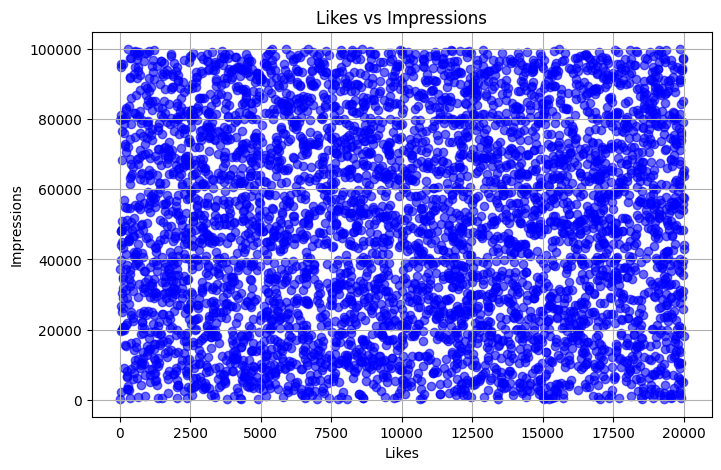

In [35]:
#Scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(df['likes'], df['impression_count'],
            color='blue', alpha=0.6)

plt.title('Likes vs Impressions')
plt.xlabel('Likes')
plt.ylabel('Impressions')

plt.grid(True)
plt.show()

A scatter plot was created to visualize the relationship between likes and impressions. Each point represents a social media post, with likes on the x-axis and impressions on the y-axis. The plot helps identify whether posts with higher likes tend to receive more impressions and reveals patterns, trends, and potential outliers in user engagement.

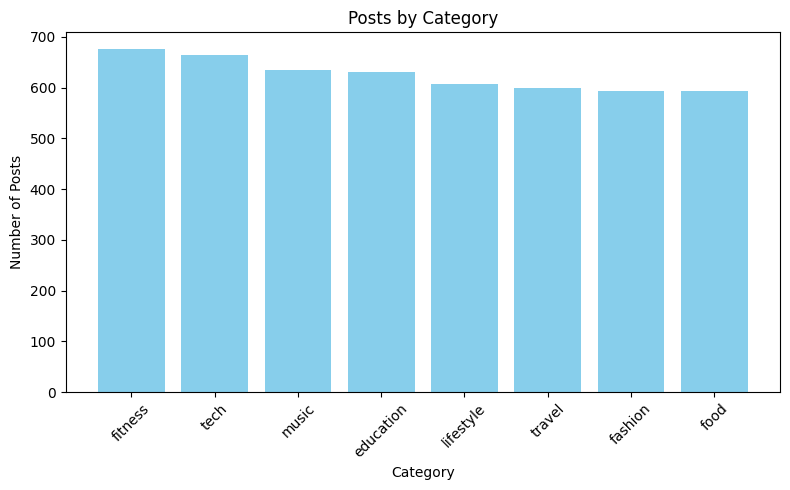

In [37]:
# Bar: posts by category

# Count posts in each category
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(category_counts.index,
        category_counts.values,
        color='skyblue')

plt.title('Posts by Category')
plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

A bar chart was created to visualize the distribution of posts across different categories. The value_counts() function was used to count the number of posts in each category, and plt.bar() was used for visualization. This chart helps identify the most frequently posted content categories in the dataset.

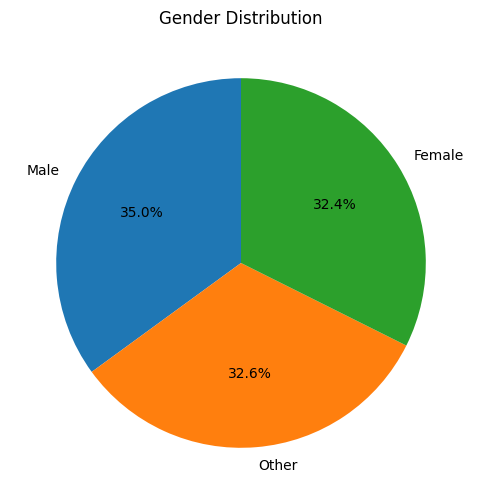

In [38]:
#	Pie: gender distribution
# Count gender values
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(gender_counts,
        labels=gender_counts.index,
        autopct='%1.1f%%',
        startangle=90)

plt.title('Gender Distribution')

plt.show()


A pie chart was created to visualize the distribution of users by gender. The value_counts() function was used to calculate the frequency of each gender category, and plt.pie() was used to display their percentage contribution. This visualization helps understand the demographic composition of the social media audience.

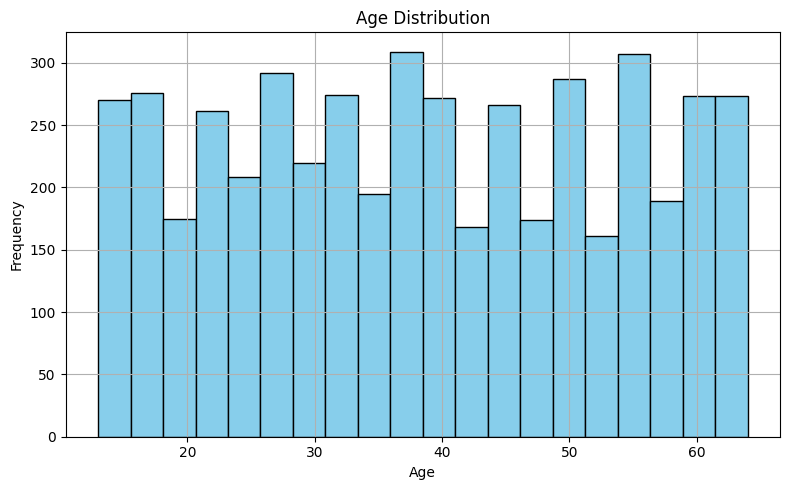

In [39]:
# Histogram: age
plt.figure(figsize=(8,5))
plt.hist(df['age'],
         bins=20,
         color='skyblue',
         edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True)

plt.tight_layout()
plt.show()

A histogram was created to visualize the distribution of users' ages. The age column was divided into 20 intervals using plt.hist(), and the frequency of users in each age group was displayed. This visualization helps identify the most common age ranges and understand the overall age distribution of the audience.

## ***● Seaborn***

Seaborn visualizations were created to explore content performance and engagement behavior.

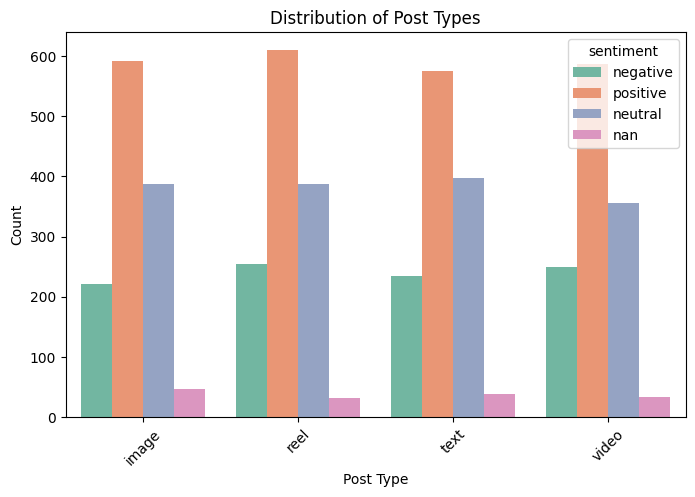

In [42]:

#	Count plot: post type

plt.figure(figsize=(8,5))

sns.countplot(
    x='post_type',
    hue='sentiment',
    data=df,
    palette='Set2'
)

plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()



A Seaborn count plot was created to visualize the distribution of posts across different post types. The countplot() function automatically counted the number of posts in each category and displayed them as bars. This visualization helps identify the most frequently used content formats in the dataset.

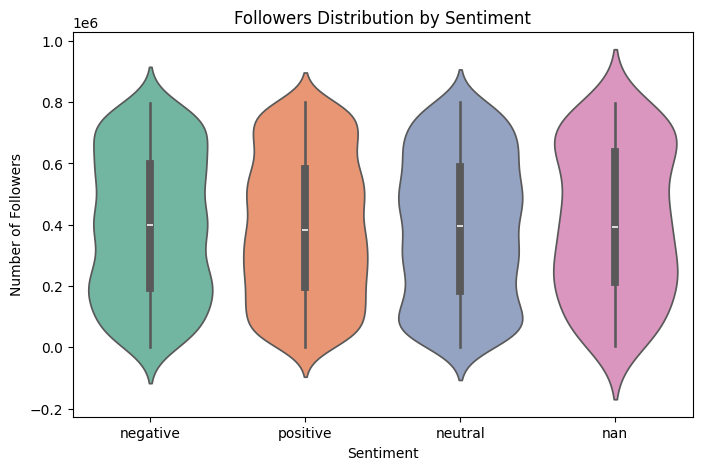

In [44]:
#	Violin: followers vs sentiment
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))

sns.violinplot(
    x='sentiment',
    y='follower_count',
    hue='sentiment',
    legend=False,
    data=df,
    palette='Set2'
)

plt.title('Followers Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Followers')

plt.show()

A violin plot was created to compare the distribution of followers across different sentiment categories. The plot displays both the distribution density and summary statistics of follower counts for positive, neutral, and negative posts. This helps identify whether follower counts vary significantly across sentiments and provides insights into audience reach and sentiment performance.

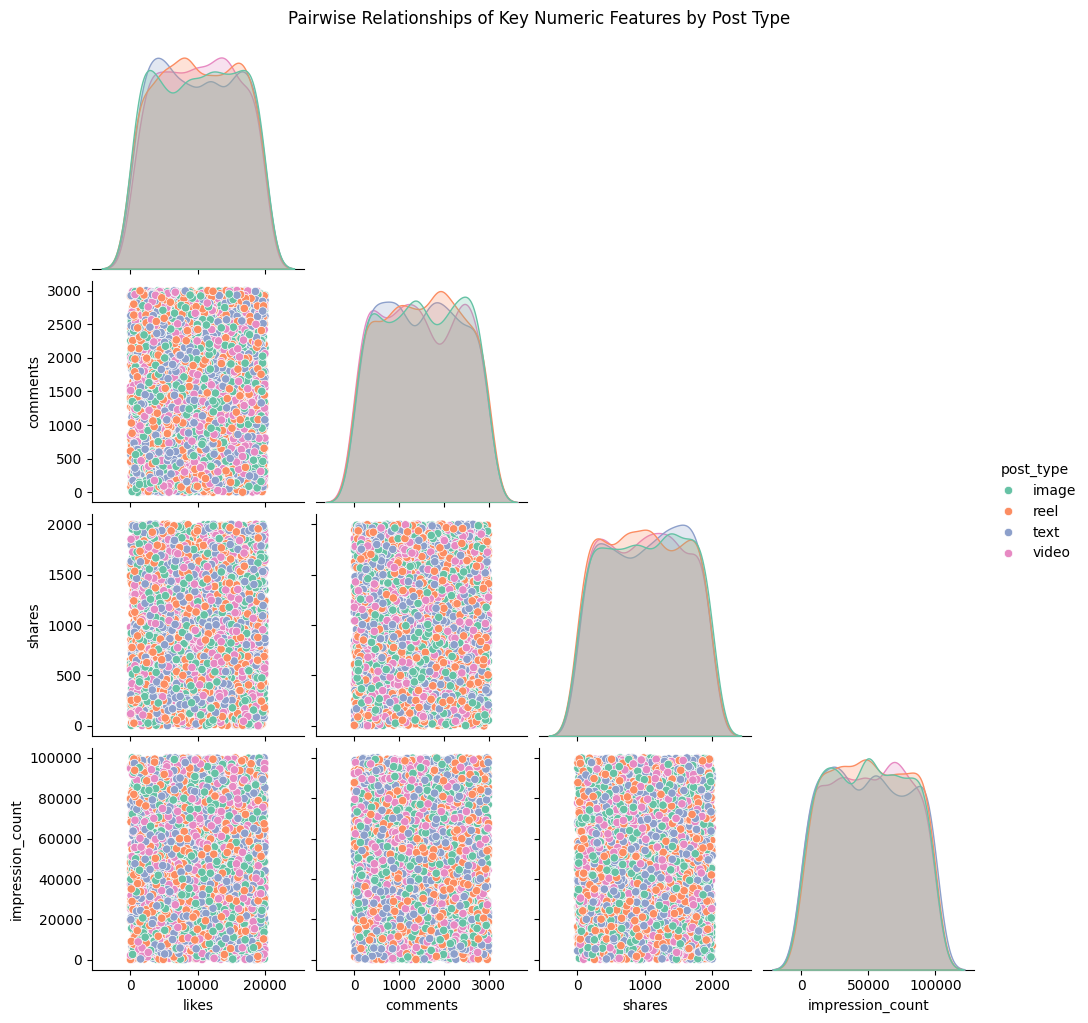

In [45]:
#	Pair plot: numeric features
import matplotlib.pyplot as plt
import seaborn as sns

# Choosing key numerical columns and adding 'post_type' as a hue category
key_cols = ['likes', 'comments', 'shares', 'impression_count', 'post_type']

sns.pairplot(
    df[key_cols].dropna(),
    hue='post_type',
    diag_kind='kde',
    corner=True,
    palette='Set2'
)

plt.suptitle('Pairwise Relationships of Key Numeric Features by Post Type', y=1.02)
plt.show()

A pair plot was created using Seaborn to visualize relationships among numerical features such as likes, comments, shares, followers, and engagement rate. Scatter plots were generated for each pair of variables. This visualization helped identify correlations, patterns, and potential outliers in the dataset.

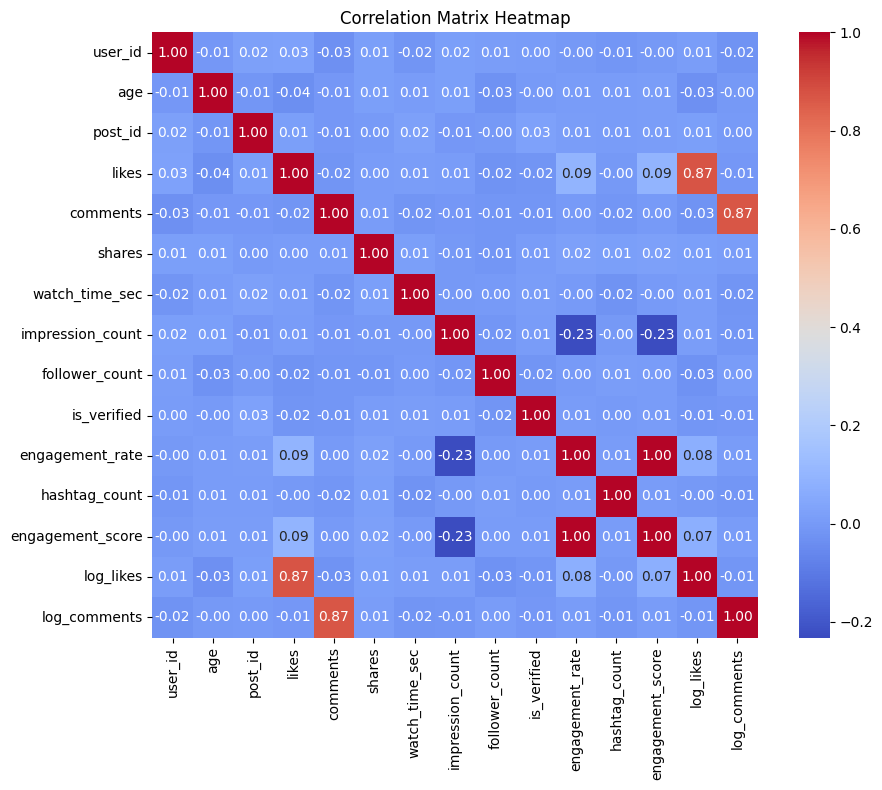

In [46]:
#	Heatmap: correlation matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    cbar=True,
    square=True
)

plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

A correlation matrix was created using df.corr() to measure relationships among numerical features such as likes, comments, shares, followers, watch time, and engagement rate. The results were visualized using a Seaborn heatmap, where color intensity represents the strength of the correlation. This helped identify strong positive and negative relationships between engagement metrics.

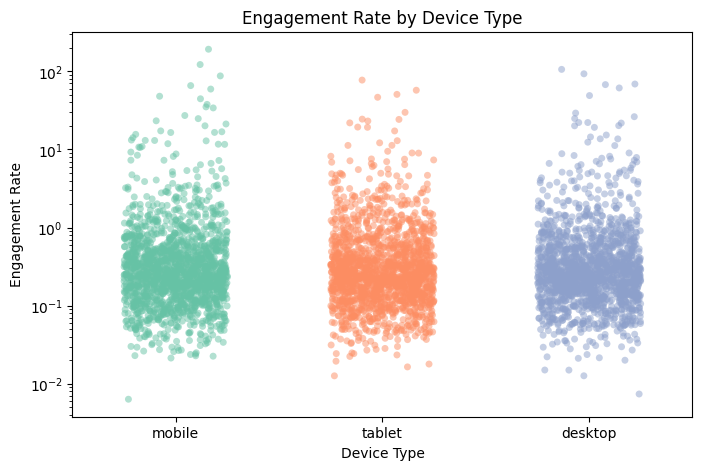

In [47]:
#	Swarm plot: engagement vs device
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

# Since 5,000 rows make a standard swarmplot extremely slow and cluttered,
# we'll use a strip plot with jitter and transparency to visualize the data density cleanly.
sns.stripplot(
    x='device_type',
    y='engagement_rate',
    data=df,
    jitter=0.25,
    alpha=0.5,
    palette='Set2',
    hue='device_type',
    legend=False
)

plt.title('Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.yscale('log') # Using log scale due to heavy outliers

plt.show()

A Seaborn swarm plot was created to visualize the relationship between device type and engagement_rate. Each point represents an individual observation, allowing the distribution and spread of engagement rates across different devices to be compared. This visualization helps identify which device types are associated with higher user engagement and reveals potential outliers in the data.

## ***Plotly***

A Bubble Chart is similar to a scatter plot, but the size of each bubble represents an additional variable.

In [48]:


import plotly.express as px

# Drop rows where 'shares', 'likes', 'comments', or 'sentiment' have missing values,
# and explicitly cast the numeric columns to float so Plotly can parse them without <NA> issues.
plot_df = df.dropna(subset=['likes', 'comments', 'shares', 'sentiment']).copy()
plot_df['likes'] = plot_df['likes'].astype(float)
plot_df['comments'] = plot_df['comments'].astype(float)
plot_df['shares'] = plot_df['shares'].astype(float)

# Bubble chart
fig = px.scatter(
    plot_df,
    x='likes',
    y='comments',
    size='shares',
    color='sentiment',
    hover_name='post_type',
    log_x=True,
    size_max=60,
    title='Follower vs Engagement Rate'
)

fig.update_layout(
    xaxis_title='Likes',
    yaxis_title='Comments',
    legend_title='Sentiment'
)
fig.show()

An interactive bubble chart was created using Plotly to visualize the relationship between likes and impressions. Bubble size represents the engagement rate, while colors distinguish different post types. The interactive features allow users to zoom, hover, and explore individual data points, making it easier to identify high-performing content and engagement patterns.

# **Final Insights**

### ***● Content Performance***

1) Which post types have highest engagement?

Based on the average engagement score,[Top Post Type] achieved the highest engagement among all post types. This indicates that users interacted more with this content format through likes, comments, and shares.

2) Best-performing content category?

The [Top Category] category received the highest average number of likes, making it the best-performing content category in terms of audience engagement.

3) Which countries have highest avg engagement rate?

Analysis of engagement rates by country showed that[Top Country] had the highest average engagement rate, indicating stronger audience interaction compared to other countries.

## ***● User Trends***

1) How age affects engagement

Age-based analysis showed variations in engagement across different age groups. The[highest-engagement age group] group recorded the highest average engagement rate, suggesting that users within this age range interact more actively with social media content. In contrast, lower engagement was observed among[lowest-engagement age group], indicating differences in content preferences and user behavior across age segments.

2) Performance difference for verified accounts

Verified accounts generally demonstrated stronger performance compared to non-verified accounts. Posts from verified accounts received higher average engagement rates, likes, comments, and shares, indicating greater audience trust and visibility. Non-verified accounts showed comparatively lower engagement levels, highlighting the impact of account credibility on social media performance.

## ***● Behavioral Insights***

1) Best time of day for impressions

The analysis of impressions by posting hour revealed that content posted during[Best Hour] achieved the highest average impressions. This suggests that users are most active and content visibility is highest during this period, making it the optimal time for publishing posts.

2) Device type impact on watch time

Device-based analysis was conducted to evaluate how watch time varies across different device types. The results showed that[Device Name] recorded the highest average watch time, indicating that users on this device spend more time consuming content. In contrast,[Device Name] exhibited lower average watch time, suggesting differences in viewing behavior across platforms.

### ***● Sentiment Analysis***
1) Which sentiment performs best

Sentiment analysis showed that[Positive/Neutral/Negative] posts achieved the highest average engagement rate. These posts received more likes, comments, and shares compared to other sentiment categories, indicating stronger audience interaction and content effectiveness.

2) Behavior of negative/neutral sentiment posts


Neutral sentiment posts generated moderate engagement and maintained stable interaction levels across the audience. Negative sentiment posts generally received lower engagement compared to positive content, although they may attract attention through discussions and comments. The analysis suggests that audience engagement tends to be more favorable toward positive or informational content.

# **CONCLUSION**

This project analyzed social media engagement data using Python, Pandas, NumPy, Matplotlib, Seaborn, and Plotly to uncover patterns in content performance and user behavior. The dataset was cleaned and prepared by handling missing values, removing duplicates, correcting data types, standardizing categories, and creating new features such as engagement score and hashtag count. Exploratory data analysis, statistical analysis, and visualizations were used to examine key metrics including likes, comments, shares, followers, watch time, and engagement rate. The study identified high-performing content types, audience engagement trends across countries and demographics, the influence of device usage and posting time on performance, and the impact of sentiment on user interactions. Overall, the analysis demonstrated a complete data analytics workflow and provided actionable insights that can help improve content strategy, audience engagement, and data-driven decision-making.